In [ ]:
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display
from io import BytesIO

# Run this cell, click "Choose Files", and select:
# C:\Users\khanh\OneDrive\Desktop\Research with LisaBono\metaanalysis_data.xlsx
uploaded = files.upload()

Saving metaanalysis_data.xlsx to metaanalysis_data.xlsx


In [ ]:
filename = "metaanalysis_data.xlsx"
if filename not in uploaded:
    raise ValueError(f"Please select {filename} when uploading.")

df = pd.read_excel(
    BytesIO(uploaded[filename]),
    sheet_name=0,
    na_values=["NA", "Na", "na", "N/A", ""],
)

# Column B and Column C: receptor classifications.
classifications = {
    "B": df.columns[1],
    "C": df.columns[2],
}

# Columns D–H: five trade-off outcomes.
outcomes = list(df.columns[3:8])

# Exclude rows missing either classification.
# Do not exclude rows merely because some outcomes are missing.
df = df.dropna(subset=list(classifications.values())).copy()

# Ensure that recorded outcomes are 0 or 1.
for outcome in outcomes:
    df[outcome] = pd.to_numeric(df[outcome], errors="raise")

    invalid = df[outcome].notna() & ~df[outcome].isin([0, 1])
    if invalid.any():
        raise ValueError(
            f"Nonbinary values in {outcome}: "
            f"{df.loc[invalid, outcome].unique().tolist()}"
        )

# Estimate each marginal probability separately.
records = []

for label, classification in classifications.items():
    for category, group in df.groupby(classification, sort=True):
        for outcome in outcomes:
            observed = group[outcome].dropna()

            N = len(observed)
            S = int(observed.sum())

            records.append({
                "classification": label,
                "category": category,
                "outcome": outcome,
                "N_observed": N,
                "S_occurrences": S,
                "N_missing": len(group) - N,
                "p_empirical": S / N if N > 0 else np.nan,
            })

results = pd.DataFrame(records)

print(f"File: {filename}")
print(f"Included data rows: {len(df)}")
print("\nCounts and empirical marginal probabilities:")
display(results.round(4))

# Display the five probabilities as a vector for each category.
probability_vectors = results.pivot(
    index=["classification", "category"],
    columns="outcome",
    values="p_empirical",
).reindex(columns=outcomes)

print("\nEstimated marginal probability vectors:")
display(probability_vectors.round(4))

File: metaanalysis_data.xlsx
Included data rows: 274

Counts and empirical marginal probabilities:


,classification,category,outcome,N_observed,S_occurrences,N_missing,p_empirical
0,B,biosynthesized macromolecule-based,antibiotic_resensitization,101,78,72,0.7723
1,B,biosynthesized macromolecule-based,attenuated_virulence,116,105,57,0.9052
2,B,biosynthesized macromolecule-based,reduced_growth_rate,120,91,53,0.7583
3,B,biosynthesized macromolecule-based,phenotypic_change,155,143,18,0.9226
4,B,biosynthesized macromolecule-based,physiological_stress,83,62,90,0.7470
5,B,ribosomally encoded,antibiotic_resensitization,52,28,49,0.5385
6,B,ribosomally encoded,attenuated_virulence,48,38,53,0.7917
7,B,ribosomally encoded,reduced_growth_rate,62,34,39,0.5484
8,B,ribosomally encoded,phenotypic_change,83,71,18,0.8554
9,B,ribosomally encoded,physiological_stress,39,24,62,0.6154



Estimated marginal probability vectors:


outcome                                            antibiotic_resensitization  \
classification category                                                         
B              biosynthesized macromolecule-based                      0.7723   
               ribosomally encoded                                     0.5385   
C              context-dependent                                       0.5882   
               evolutionarily constrained                              0.8235   

outcome                                            attenuated_virulence  \
classification category                                                   
B              biosynthesized macromolecule-based                0.9052   
               ribosomally encoded                               0.7917   
C              context-dependent                                 0.8384   
               evolutionarily constrained                        0.9231   

outcome                                            reduced_growth_rate  \
classification category                                                  
B              biosynthesized macromolecule-based               0.7583   
               ribosomally encoded                              0.5484   
C              context-dependent                                0.6078   
               evolutionarily constrained                       0.7875   

outcome                                            phenotypic_change  \
classification category                                                
B              biosynthesized macromolecule-based             0.9226   
               ribosomally encoded                            0.8554   
C              context-dependent                              0.9097   
               evolutionarily constrained                     0.8830   

outcome                                            physiological_stress  
classification category                                                  
B              biosynthesized macromolecule-based                0.7470  
               ribosomally encoded                               0.6154  
C              context-dependent                                 0.7000  
               evolutionarily constrained                        0.7115

Saving metaanalysis_data.xlsx to metaanalysis_data.xlsx
File: metaanalysis_data.xlsx
Included rows: 274
Number of sensitivity results: 420
classification                           category                    outcome  N_observed  S_occurrences  N_missing  p_observed      q  expected_Q   sd_Q  lower_95  upper_95
             B biosynthesized macromolecule-based antibiotic_resensitization         101             78         72      0.7723 0.0000      0.4509 0.0000    0.4509    0.4509
             B biosynthesized macromolecule-based antibiotic_resensitization         101             78         72      0.7723 0.0500      0.4717 0.0107    0.4566    0.4971
             B biosynthesized macromolecule-based antibiotic_resensitization         101             78         72      0.7723 0.1000      0.4925 0.0147    0.4682    0.5260
             B biosynthesized macromolecule-based antibiotic_resensitization         101             78         72      0.7723 0.1500      0.5133 0.0175    0.4798    0.5

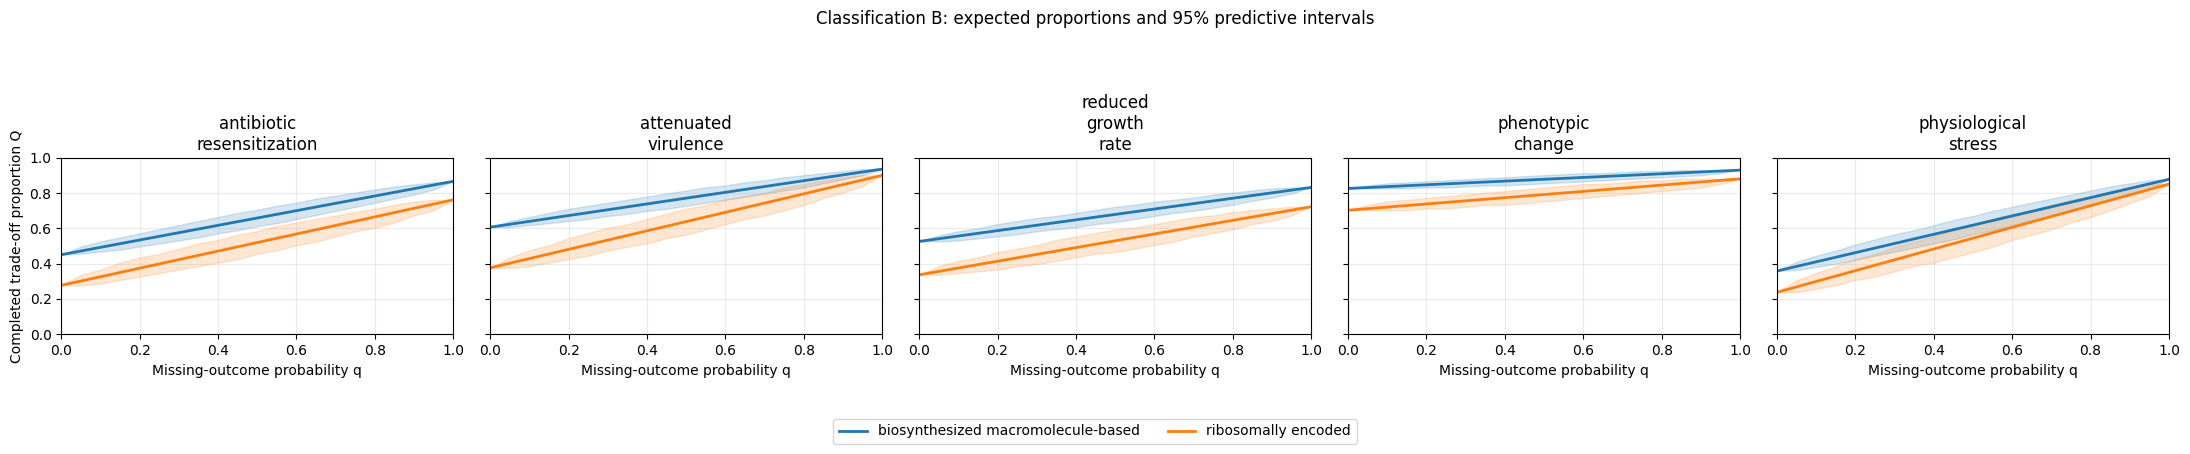

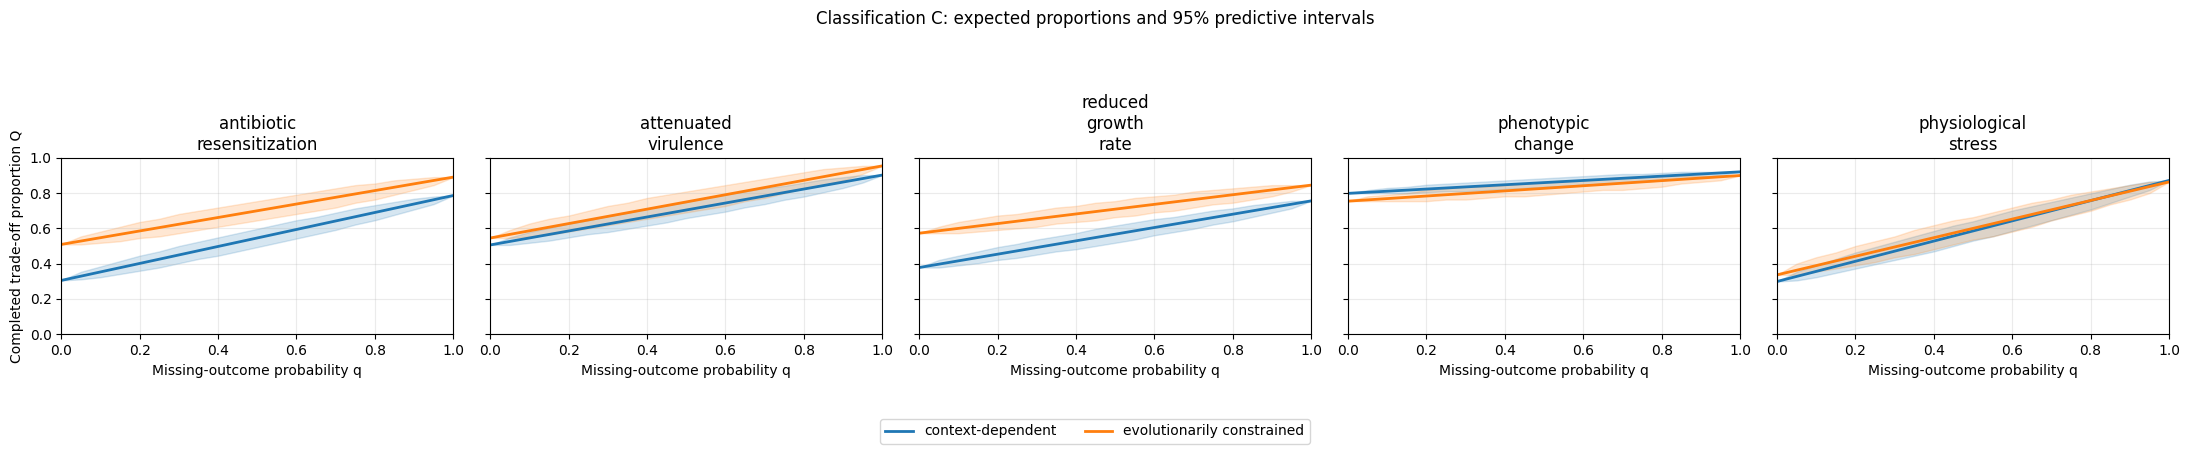

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import binom
from google.colab import files
from IPython.display import display
from io import BytesIO

# 1. Upload your Excel file.
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_excel(
    BytesIO(uploaded[filename]),
    sheet_name=0,
    na_values=["NA", "Na", "na", "N/A", ""],
)

# Columns B and C: classifications.
# Columns D–H: trade-off outcomes.
classifications = {"B": df.columns[1], "C": df.columns[2]}
outcomes = list(df.columns[3:8])

df = df.dropna(subset=list(classifications.values())).copy()

for outcome in outcomes:
    df[outcome] = pd.to_numeric(df[outcome], errors="raise")

    invalid = df[outcome].notna() & ~df[outcome].isin([0, 1])
    if invalid.any():
        raise ValueError(f"Nonbinary values found in {outcome}")

# 2. Specify the range of missing-outcome probabilities.
q_values = np.linspace(0, 1, 21)  # 0, 0.05, ..., 1
interval_level = 0.95
tail = (1 - interval_level) / 2

# 3. For each category and outcome:
#    K | q ~ Binomial(M, q)
#    Q = (S + K) / (N + M)
records = []

for label, classification in classifications.items():
    for category, group in df.groupby(classification, sort=True):
        for outcome in outcomes:

            observed = group[outcome].dropna()
            N = len(observed)
            S = int(observed.sum())
            M = len(group) - N
            T = N + M

            for q in q_values:
                expected_Q = (S + M * q) / T
                variance_Q = M * q * (1 - q) / T**2

                # Exact binomial quantiles, without simulation.
                # Coverage can exceed 95% because K is discrete.
                lower_K = binom.ppf(tail, M, q)
                upper_K = binom.ppf(1 - tail, M, q)

                records.append({
                    "classification": label,
                    "category": category,
                    "outcome": outcome,
                    "N_observed": N,
                    "S_occurrences": S,
                    "N_missing": M,
                    "p_observed": S / N if N > 0 else np.nan,
                    "q": q,
                    "expected_Q": expected_Q,
                    "sd_Q": np.sqrt(variance_Q),
                    "lower_95": (S + lower_K) / T,
                    "upper_95": (S + upper_K) / T,
                })

results = pd.DataFrame(records)

print(f"File: {filename}")
print(f"Included rows: {len(df)}")
print(f"Number of sensitivity results: {len(results)}")

# Print every row rather than truncating the results.
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 4. Plot sensitivity curves and conditional predictive intervals.
for label in classifications:
    fig, axes = plt.subplots(
        1, len(outcomes),
        figsize=(22, 4.5),
        sharex=True,
        sharey=True,
    )

    for ax, outcome in zip(axes, outcomes):
        subset = results[
            (results["classification"] == label)
            & (results["outcome"] == outcome)
        ]

        for category, group in subset.groupby("category", sort=True):
            group = group.sort_values("q")

            x = group["q"].to_numpy()
            mean = group["expected_Q"].to_numpy()
            lower = group["lower_95"].to_numpy()
            upper = group["upper_95"].to_numpy()

            line, = ax.plot(x, mean, linewidth=2, label=category)
            ax.fill_between(
                x, lower, upper,
                color=line.get_color(),
                alpha=0.18,
            )

        ax.set_title(outcome.replace("_", "\n"))
        ax.set_xlabel("Missing-outcome probability q")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.25)

    axes[0].set_ylabel("Completed trade-off proportion Q")
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0),
        ncol=2,
    )
    fig.suptitle(
        f"Classification {label}: expected proportions "
        "and 95% predictive intervals"
    )
    fig.tight_layout(rect=[0, 0.13, 1, 0.90])
    plt.show()

# 5. Download the full results.
output_file = "missing_outcome_q_sensitivity.csv"
results.to_csv(output_file, index=False)
files.download(output_file)

In [2]:
# 6. Generate LaTeX table.

latex_results = results.copy()

# Combine the lower and upper bounds into one column.
latex_results["95% Predictive Interval"] = (
    "[" + latex_results["lower_95"].map("{:.4f}".format)
    + ", " + latex_results["upper_95"].map("{:.4f}".format) + "]"
)

# Select and rename columns.
latex_table = latex_results[
    [
        "classification",
        "category",
        "outcome",
        "N_observed",
        "S_occurrences",
        "N_missing",
        "p_observed",
        "q",
        "expected_Q",
        "sd_Q",
        "95% Predictive Interval",
    ]
].copy()

latex_table.columns = [
    "Class.",
    "Category",
    "Outcome",
    "$N$",
    "$S$",
    "$M$",
    "$\\hat{p}_{\\mathrm{obs}}$",
    "$q$",
    "$\\mathbb{E}[Q\\mid q]$",
    "$\\mathrm{SD}(Q\\mid q)$",
    "95\\% PI",
]

# Convert to LaTeX.
latex_code = latex_table.to_latex(
    index=False,
    escape=False,
    float_format="%.4f",
    longtable=True,
    caption=(
        "Sensitivity analysis of trade-off proportions "
        "under missing outcome uncertainty."
    ),
    label="tab:missing_outcome_sensitivity",
)

# Save the LaTeX code.
with open("missing_outcome_sensitivity.tex", "w") as f:
    f.write(latex_code)

# Display and download.
print(latex_code)
files.download("missing_outcome_sensitivity.tex")

\begin{longtable}{lllrrrrrrrl}
\caption{Sensitivity analysis of trade-off proportions under missing outcome uncertainty.} \label{tab:missing_outcome_sensitivity} \\
\toprule
Class. & Category & Outcome & $N$ & $S$ & $M$ & $\hat{p}_{\mathrm{obs}}$ & $q$ & $\mathbb{E}[Q\mid q]$ & $\mathrm{SD}(Q\mid q)$ & 95\% PI \\
\midrule
\endfirsthead
\caption[]{Sensitivity analysis of trade-off proportions under missing outcome uncertainty.} \\
\toprule
Class. & Category & Outcome & $N$ & $S$ & $M$ & $\hat{p}_{\mathrm{obs}}$ & $q$ & $\mathbb{E}[Q\mid q]$ & $\mathrm{SD}(Q\mid q)$ & 95\% PI \\
\midrule
\endhead
\midrule
\multicolumn{11}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
B & biosynthesized macromolecule-based & antibiotic_resensitization & 101 & 78 & 72 & 0.7723 & 0.0000 & 0.4509 & 0.0000 & [0.4509, 0.4509] \\
B & biosynthesized macromolecule-based & antibiotic_resensitization & 101 & 78 & 72 & 0.7723 & 0.0500 & 0.4717 & 0.0107 & [0.4566, 0.4971] \\
B & biosynthesi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>